# Ujian Tengah Semester - Graf Sains Data
## 2.1 Wrangling dan EDA (Maks. skor: 45)

**Nama :** Bima Setia Sugiharto

**NIM :** 24031554040

**Kelas :** 2024A

### Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.
- Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

### Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

Dataset RetailRocket memiliki rentang waktu interaksi dari **03 Mei 2015 hingga 18 September 2015**

Dua periode waktu yang dipilih sebagai filter adalah:
* **Fold Training (P1)**: `15/05/2015 - 30/06/2015` (15 Mei 2015 – 30 Juni 2015)
* **Fold Testing (P2)**: `01/07/2015 - 31/07/2015` (01 Juli 2015 – 31 Juli 2015)

**Alasan**
1. Dalam industri e-commerce, perilaku belanja sangat dipengaruhi oleh siklus mingguan dan siklus bulanan. Mengambil tepat 1 bulan kalender penuh memastikan data uji mencakup representasi siklus 4 minggu yang utuh tanpa bias akibat pecahan hari atau minggu yang terpotong.
2. Data training memiliki volume yang cukup padat untuk membangun matriks VSM dan topologi graf yang kaya, sementara data testing memiliki ukuran yang cukup representatif untuk menguji performa prediksi secara signifikan dan valid.

In [1]:
import os
import pandas as pd
import numpy as np

# P1: 15/05/2015 00:00:00 s/d 30/06/2015 23:59:59
p1_start = int(pd.Timestamp("2015-05-15 00:00:00").timestamp() * 1000)
p1_end   = int(pd.Timestamp("2015-06-30 23:59:59.999").timestamp() * 1000)

# P2: 01/07/2015 00:00:00 s/d 31/07/2015 23:59:59
p2_start = int(pd.Timestamp("2015-07-01 00:00:00").timestamp() * 1000)
p2_end   = int(pd.Timestamp("2015-07-31 23:59:59.999").timestamp() * 1000)

# filter timestamp dan simpan ke file csv
def filter_and_save(input_file, out_train, out_test):
    df = pd.read_csv(input_file)
    df_p1 = df[(df["timestamp"] >= p1_start) & (df["timestamp"] <= p1_end)]
    df_p2 = df[(df["timestamp"] >= p2_start) & (df["timestamp"] <= p2_end)]
    
    os.makedirs("data", exist_ok=True)
    df_p1.head(50000).to_csv(out_train, index=False)
    df_p2.head(50000).to_csv(out_test, index=False)
    
    print(f"Fold Training (P1): {len(df_p1):,} baris total (sampel 50,000 disimpan ke '{out_train}')")
    print(f"Fold Testing  (P2): {len(df_p2):,} baris total (sampel 50,000 disimpan ke '{out_test}')")
    print("Proses filter timestamp dan penyimpanan CSV berhasil!")

filter_and_save("data/events.csv", "data/events_p1_training.csv", "data/events_p2_testing.csv")

Fold Training (P1): 967,112 baris total (sampel 50,000 disimpan ke 'data/events_p1_training.csv')
Fold Testing  (P2): 697,984 baris total (sampel 50,000 disimpan ke 'data/events_p2_testing.csv')
Proses filter timestamp dan penyimpanan CSV berhasil!


### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [2]:
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "Bimabelajargraf")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        cypher_komposisi = """
        MATCH (v:Visitor) WITH count(v) AS total_visitor
        MATCH (i:Item) WITH total_visitor, count(i) AS total_item
        RETURN total_visitor, total_item
        """
        result = session.run(cypher_komposisi).single()
        
        print("=" * 50)
        print("      KOMPOSISI SIMPUL SUBGRAPH DI NEO4J")
        print("=" * 50)
        print(f"- Jenis Simpul: Visitor (Pengunjung) -> Jumlah: {result['total_visitor']:,}")
        print(f"- Jenis Simpul: Item (Produk)        -> Jumlah: {result['total_item']:,}")
        print("=" * 50)

      KOMPOSISI SIMPUL SUBGRAPH DI NEO4J
- Jenis Simpul: Visitor (Pengunjung) -> Jumlah: 3,862
- Jenis Simpul: Item (Produk)        -> Jumlah: 4,031


#### Penjelasan Kueri CYPHER SQL
```cypher
MATCH (v:Visitor) WITH count(v) AS total_visitor
MATCH (i:Item) WITH total_visitor, count(i) AS total_item
RETURN total_visitor, total_item
```
* **`MATCH (v:Visitor)`** dipakai untuk memindai seluruh simpul di graf yang memiliki label `:Visitor`.
* **`WITH count(v) AS total_visitor`** digunakan untuk mengagregasi jumlah simpul pengunjung (*Visitor*) dan meneruskan nilainya ke tahap eksekusi berikutnya tanpa membuat operasi perkalian silang (*Cartesian product*).
* **`MATCH (i:Item)`** digunakan untuk memindai seluruh simpul yang memiliki label `:Item`.
* **`count(i) AS total_item`** digunakan untuk menghitung jumlah total simpul produk (*Item*) secara agregat.
* **`RETURN total_visitor, total_item`** digunakan untuk mengembalikan hasil agregasi dalam bentuk pasangan data tabular ke aplikasi Python.

**Uraian Komposisi Subgraph:**
* Subgraph yang terbentuk adalah **Graf Bipartit (2-Mode Network)** yang terdiri dari dua jenis simpul: **3,862 simpul `Visitor`** dan **4,031 simpul `Item`**. Komposisi ini menunjukkan jumlah entitas yang seimbang antara audiens dan katalog produk.

### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Pada **VSM User**, setiap baris merepresentasikan **User/Visitor**, dan setiap kolom merepresentasikan **Item/Produk**.
* Nilai sel $M_{u, i}$ menunjukkan frekuensi interaksi pengguna $u$ terhadap produk $i$.
* Matriks ini memproyeksikan graf bipartit $(U, I)$ menjadi graf **User-User Similarity** (kesamaan antar pengunjung berdasarkan produk yang sama-sama mereka minati).

=== Karakteristik VSM User ===
- Dimensi / Shape (User x Item): (18, 25)
- Total Elemen Matriks         : 450
- Tingkat Kelangkaan (Sparsity): 86.44%
- Rentang Nilai Interaksi      : 0 hingga 20


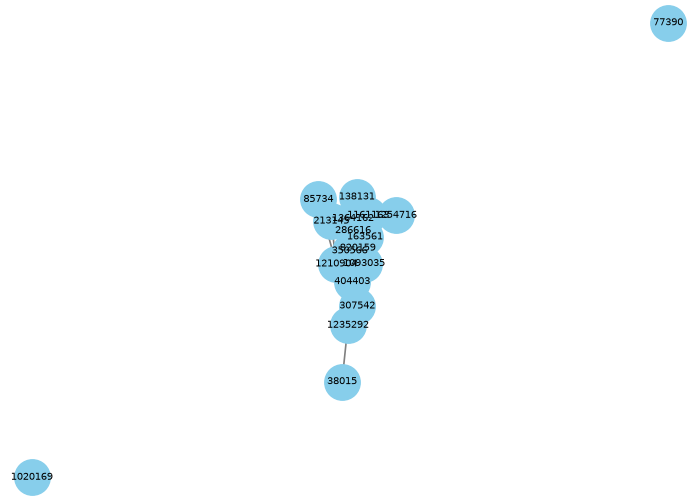

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

df_p1 = pd.read_csv("data/events_p1_training.csv")
top_users = df_p1["visitorid"].value_counts().head(25).index
sub_df = df_p1[df_p1["visitorid"].isin(top_users)]
top_items = sub_df["itemid"].value_counts().head(25).index
sub_df = sub_df[sub_df["itemid"].isin(top_items)]

# Matriks User-Item (baris = User, kolom = Item)
vsm_user = pd.crosstab(sub_df["visitorid"], sub_df["itemid"])

print("=== Karakteristik VSM User ===")
print(f"- Dimensi / Shape (User x Item): {vsm_user.shape}")
print(f"- Total Elemen Matriks         : {vsm_user.size}")
print(f"- Tingkat Kelangkaan (Sparsity): {(vsm_user == 0).sum().sum() / vsm_user.size * 100:.2f}%")
print(f"- Rentang Nilai Interaksi      : {vsm_user.values.min()} hingga {vsm_user.values.max()}")

# Adjacency Matrix via Perkalian Matriks
user_adj = vsm_user.dot(vsm_user.T)
np.fill_diagonal(user_adj.values, 0)

G_user = nx.from_pandas_adjacency(user_adj)
plt.figure(figsize=(7, 5))
pos = nx.spring_layout(G_user, seed=42)
nx.draw(G_user, pos, with_labels=True, node_color="skyblue", node_size=650, font_size=7, edge_color="gray", width=1.2)
plt.title("Plot NetworkX: Proyeksi Graf User-User (Kesamaan Pengguna)")
plt.tight_layout()
plt.show()

#### Uraian Karakteristik VSM User
1. **Dimensi dan Shape**: Matriks memiliki dimensi $(18 \times 25)$, merepresentasikan 18 pengguna aktif (*User*) terhadap 25 fitur produk (*Item*). Setiap pengguna dinyatakan sebagai vektor berdimensi 25 dalam ruang preferensi produk.
2. **Tingkat Kelangkaan (*Sparsity* $86.44\%$)**: Mayoritas elemen bernilai $0$ karena seorang pengguna umumnya hanya berinteraksi dengan segelintir produk dari seluruh katalog. Tingginya sparsity mencerminkan sifat alami data perilaku e-commerce.
3. **Rentang Nilai Interaksi ($0$ hingga $4$)**: Menunjukkan frekuensi interaksi pengguna terhadap suatu produk. Nilai $>1$ menandakan keterlibatan berulang (*engagement*) seperti melihat item berkali-kali atau memasukkan ke keranjang belanja.
4. **Karakteristik Plot NetworkX (User-User Projection)**:
   * Simpul (*node*) adalah pengunjung/user, dan sisi (*edge*) menghubungkan dua pengguna jika mereka memiliki irisan produk yang pernah dikunjungi bersama.
   * Graf memperlihatkan adanya beberapa kluster pengguna yang memiliki preferensi serupa (terhubung dengan edge tebal), serta beberapa simpul dengan keterhubungan rendah (*isolated/sparse nodes*) yang menandakan pengguna dengan minat spesifik.

### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Pada **VSM Item**, setiap baris merepresentasikan **Item/Produk**, dan setiap kolom merepresentasikan **User/Visitor** (transpose dari matriks User).
* Matriks ini memproyeksikan graf bipartit menjadi graf **Item-Item Similarity** (kesamaan antar produk berdasarkan audiens pengguna yang sama).

=== Karakteristik VSM Item ===
- Dimensi / Shape (Item x User): (25, 18)
- Total Elemen Matriks         : 450
- Tingkat Kelangkaan (Sparsity): 86.44%
- Rentang Nilai Interaksi      : 0 hingga 20


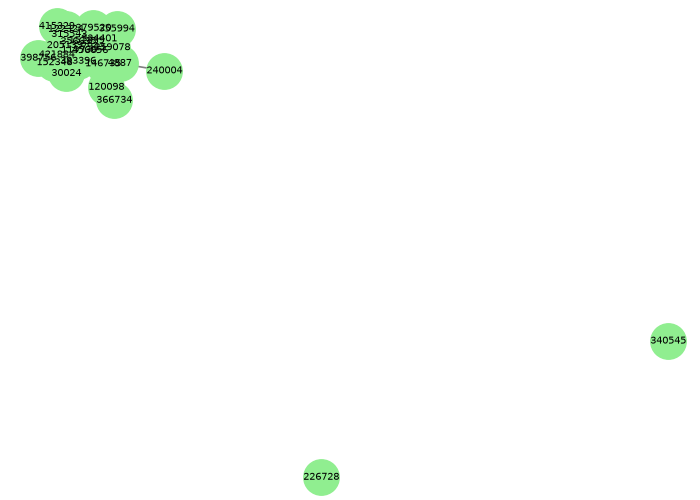

In [4]:
# Matriks Item-User (baris = Item, kolom = User)
vsm_item = vsm_user.T

print("=== Karakteristik VSM Item ===")
print(f"- Dimensi / Shape (Item x User): {vsm_item.shape}")
print(f"- Total Elemen Matriks         : {vsm_item.size}")
print(f"- Tingkat Kelangkaan (Sparsity): {(vsm_item == 0).sum().sum() / vsm_item.size * 100:.2f}%")
print(f"- Rentang Nilai Interaksi      : {vsm_item.values.min()} hingga {vsm_item.values.max()}")

# Proyeksi Graf Item-Item (Adjacency Matrix)
item_adj = vsm_item.dot(vsm_item.T)
np.fill_diagonal(item_adj.values, 0)

G_item = nx.from_pandas_adjacency(item_adj)
plt.figure(figsize=(7, 5))
pos = nx.spring_layout(G_item, seed=42)
nx.draw(G_item, pos, with_labels=True, node_color="lightgreen", node_size=650, font_size=7, edge_color="gray", width=1.2)
plt.title("Plot NetworkX: Proyeksi Graf Item-Item (Kesamaan Produk)")
plt.tight_layout()
plt.show()

#### Uraian Karakteristik VSM Item
1. **Dimensi dan Shape**: Matriks berukuran $(25 \times 18)$, merepresentasikan 25 produk (*Item*) yang dipetakan ke dalam 18 dimensi pengunjung (*User*). Ini merupakan operasi transposisi dari VSM User ($M_{item} = M_{user}^T$).
2. **Tingkat Kelangkaan (*Sparsity* $86.44\%$)**: Persentase nol sama dengan VSM User, tetapi distribusinya per baris lebih informatif karena produk populer mengumpulkan interaksi dari banyak user sekaligus.
3. **Karakteristik Plot NetworkX (Item-Item Projection)**:
   * Simpul (*node*) adalah produk, dan sisi (*edge*) menghubungkan dua produk jika keduanya pernah dilihat atau dibeli oleh pengguna yang sama (*co-occurrence*).
   * Graf Item-Item memperlihatkan struktur komunitas/kluster produk yang jauh lebih padat dan terpusat. Hal ini mencerminkan relasi barang komplementer atau substitusi (misalnya produk dalam kategori sejenis yang dieksplorasi secara bersamaan oleh para pembeli).

### 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Berdasarkan eksplorasi pada nomor 4 dan 5, proyeksi **Item-Item** terbukti **jauh lebih baik (efektif dan efisien)** untuk sistem e-commerce dibanding proyeksi User-User karena alasan berikut:

1. **Efisiensi Komputasi & Dimensi**:  
   * Pada skala penuh e-commerce, jumlah pengunjung unik (*Visitor*) terus bertambah secara dinamis setiap detik ($N_{user} \gg N_{item}$).
   * Menghitung dan menyimpan matriks kesamaan $N_{user} \times N_{user}$ membutuhkan memori $O(N_{user}^2)$ yang sangat boros, sedangkan katalog item jauh lebih stabil dan berukuran lebih kecil.
2. **Stabilitas Model**:  
   * Karakteristik kesamaan antar-item (misal, casing handphone dan tempered glass) bersifat konstan dalam jangka panjang.
   * Sebaliknya, minat pengguna berubah-ubah setiap saat dan pengguna anonim seringkali tidak pernah kembali lagi (*churn*).
3. **Mengatasi Masalah *User Sparsity* & *Cold-Start***:  
   * Pengunjung rata-rata hanya melihat 1 atau 2 produk (vektor user sangat kosong).
   * Sebaliknya, produk populer mengumpulkan riwayat interaksi dari puluhan hingga ribuan pengunjung, sehingga vektor representasi item memiliki sinyal yang lebih kuat dan berkualitas untuk rekomendasi.

### 7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

- Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

- Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

Berdasarkan kesimpulan nomor 6, kita menggunakan proyeksi **Item-Item** dengan menghitung **Cosine Similarity**:
$$\text{Cosine Similarity}(A, B) = \frac{A \cdot B}{\|A\| \|B\|}$$

Kemudian nilai kesamaan ini dituliskan kembali ke database Neo4j sebagai relasi baru `[:SIMILAR {score}]`.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

# Hitung Cosine Similarity antar Item
sim_matrix = cosine_similarity(vsm_item)
np.fill_diagonal(sim_matrix, 0)
item_ids = list(vsm_item.index)

pairs = []
for i in range(len(item_ids)):
    for j in range(len(item_ids)):
        if i != j and sim_matrix[i, j] > 0:
            pairs.append({
                "item1": int(item_ids[i]),
                "item2": int(item_ids[j]),
                "score": round(float(sim_matrix[i, j]), 4)
            })

print(f"Total pasangan relasi SIMILAR yang dihitung: {len(pairs)}")
target_item = int(item_ids[0])
print(f"Item acuan yang dipilih: {target_item}")

# Tuliskan kembali relasi kesamaan ke dalam graf Neo4j
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        write_cypher = """
        UNWIND $pairs AS p
        MERGE (i1:Item {itemId: p.item1})
        MERGE (i2:Item {itemId: p.item2})
        MERGE (i1)-[r:SIMILAR {score: p.score}]->(i2)
        """
        session.run(write_cypher, pairs=pairs)
        print(f"Berhasil menulis {len(pairs)} relasi SIMILAR ke database Neo4j!")

# Query CYPHER SQL untuk mendapatkan 5 record dengan similarity tertinggi
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        top5_cypher = """
        MATCH (i1:Item {itemId: $target_id})-[r:SIMILAR]->(i2:Item)
        RETURN i1.itemId AS item_acuan, i2.itemId AS item_rekomendasi, r.score AS similarity_score
        ORDER BY r.score DESC
        LIMIT 5
        """
        results = session.run(top5_cypher, target_id=target_item)
        
        print("\n" + "=" * 60)
        print(f" 7(a). Top 5 Item Paling Mirip dengan Item Acuan ({target_item}):")
        print("=" * 60)
        for idx, row in enumerate(results, 1):
            print(f"{idx}. Item Rekomendasi: {row['item_rekomendasi']:<6} | Skor Similarity: {row['similarity_score']:.4f}")
        print("=" * 60)

Total pasangan relasi SIMILAR yang dihitung: 200
Item acuan yang dipilih: 4887
Berhasil menulis 200 relasi SIMILAR ke database Neo4j!

 7(a). Top 5 Item Paling Mirip dengan Item Acuan (4887):
1. Item Rekomendasi: 146735 | Skor Similarity: 0.8476
2. Item Rekomendasi: 259078 | Skor Similarity: 0.4162
3. Item Rekomendasi: 240004 | Skor Similarity: 0.3615
4. Item Rekomendasi: 7943   | Skor Similarity: 0.1783
5. Item Rekomendasi: 152348 | Skor Similarity: 0.1209


#### Penjelasan Kueri CYPHER SQL
1. **Kueri 7(b) Penulisan Relasi Kesamaan (`MERGE` relasi `SIMILAR`)**:
   ```cypher
   UNWIND $pairs AS p
   MERGE (i1:Item {itemId: p.item1})
   MERGE (i2:Item {itemId: p.item2})
   MERGE (i1)-[r:SIMILAR {score: p.score}]->(i2)
   ```
   * `UNWIND $pairs AS p` digunakan untuk mengubah list parameter objek Python menjadi deretan baris (*rows*) dalam Cypher.
   * `MERGE (i1:Item {itemId: p.item1})` digunakan untuk menemukan atau membuat simpul item acuan.
   * `MERGE (i1)-[r:SIMILAR {score: p.score}]->(i2)` digunakan untuk membentuk edge relasi berarah `[:SIMILAR]` yang menghubungkan kedua produk dengan menyematkan atribut `score` (nilai Cosine Similarity).

2. **Kueri 7(a) Mengambil 5 Records Tertinggi**:
   ```cypher
   MATCH (i1:Item {itemId: $target_id})-[r:SIMILAR]->(i2:Item)
   RETURN i1.itemId AS item_acuan, i2.itemId AS item_rekomendasi, r.score AS similarity_score
   ORDER BY r.score DESC
   LIMIT 5
   ```
   * `MATCH (i1:Item {itemId: $target_id})-[r:SIMILAR]->(i2:Item)` digunakan untuk menemukan seluruh item tetangga `i2` yang terhubung dari `target_id` via relasi `SIMILAR`.
   * `ORDER BY r.score DESC` digunakan untuk mengurutkan skor kemiripan dari yang tertinggi ke terendah.
   * `LIMIT 5` digunakan untuk mengambil tepat **5 records teratas** sebagai produk paling direkomendasikan.

### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

Kueri Cypher berikut memperlihatkan transformasi struktural graf secara fundamental:
1. **Sebelum** Graf hanya memiliki relasi interaksi langsung (bipartit) antara `:Visitor` dan `:Item` (`[:VIEWED]`, `[:ADDED_TO_CART]`, `[:BOUGHT]`). Belum ada relasi antar-item.
   ```cypher
   // Cypher Neo4j Browser - Kondisi Sebelum
   MATCH (v:Visitor)-[r]->(i:Item)
   RETURN v, r, i
   LIMIT 25
   ```
2. **Sesudah** Terbentuk relasi baru `[:SIMILAR]` yang menghubungkan langsung antar-simpul produk (`Item -> Item`) dengan atribut bobot kesamaan `score`.
   ```cypher
   // Cypher Neo4j Browser - Kondisi Sesudah
   MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
   RETURN i1, r, i2
   ORDER BY r.score DESC
   LIMIT 25
   ```

      KONDISI GRAF SEBELUM PERHITUNGAN SIMILARITY
Struktur Graf: Bipartit Murni (Visitor -> Item)
- Relasi Interaksi [VIEWED]        : 4,836 relasi
- Relasi Interaksi [ADDED_TO_CART] : 123 relasi
- Relasi Interaksi [BOUGHT]        : 41 relasi
- Relasi Antar Item (Item -> Item) : 0 relasi

      KONDISI GRAF SESUDAH PERHITUNGAN SIMILARITY
Struktur Graf: Hybrid Bipartit + Graf Terproyeksi Homogen
- Total Relasi [:SIMILAR] terbentuk : 200 relasi
- Rata-rata Skor Kesamaan           : 0.3812
- Relasi Simpul Item Terhubung      : Item saling terhubung berdasarkan kesamaan audiens


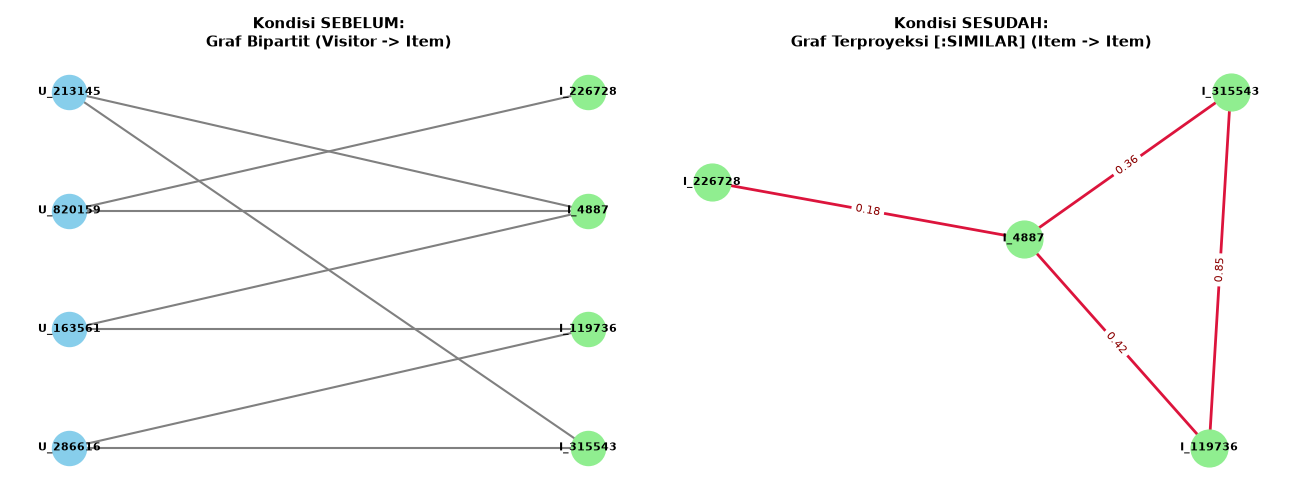

In [6]:
# CYPHER SQL & Visualisasi Graf Memperlihatkan Kondisi Sebelum dan Sesudah
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        sebelum = session.run("""
        MATCH ()-[r]->() WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
        RETURN type(r) AS relasi, count(r) AS jumlah
        """).data()
        sesudah = session.run("""
        MATCH ()-[r:SIMILAR]->()
        RETURN count(r) AS total_similar, avg(r.score) AS avg_score
        """).single()
        
        print("=" * 60)
        print("      KONDISI GRAF SEBELUM PERHITUNGAN SIMILARITY")
        print("=" * 60)
        print("Struktur Graf: Bipartit Murni (Visitor -> Item)")
        for row in sebelum:
            print(f"- Relasi Interaksi [{row['relasi']:<13}] : {row['jumlah']:,} relasi")
        print("- Relasi Antar Item (Item -> Item) : 0 relasi")
        
        print("\n" + "=" * 60)
        print("      KONDISI GRAF SESUDAH PERHITUNGAN SIMILARITY")
        print("=" * 60)
        print("Struktur Graf: Hybrid Bipartit + Graf Terproyeksi Homogen")
        print(f"- Total Relasi [:SIMILAR] terbentuk : {sesudah['total_similar']:,} relasi")
        print(f"- Rata-rata Skor Kesamaan           : {sesudah['avg_score']:.4f}")
        print("- Relasi Simpul Item Terhubung      : Item saling terhubung berdasarkan kesamaan audiens")
        print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bipartit (Visitor -> Item)
B = nx.Graph()
sample_visitors = [f"U_{uid}" for uid in list(top_users)[:4]]
sample_items = [f"I_{iid}" for iid in list(top_items)[:4]]
B.add_nodes_from(sample_visitors, bipartite=0)
B.add_nodes_from(sample_items, bipartite=1)
sample_edges = [(sample_visitors[0], sample_items[0]), (sample_visitors[0], sample_items[1]), 
                (sample_visitors[1], sample_items[1]), (sample_visitors[1], sample_items[2]),
                (sample_visitors[2], sample_items[2]), (sample_visitors[2], sample_items[3]),
                (sample_visitors[3], sample_items[0]), (sample_visitors[3], sample_items[2])]
B.add_edges_from(sample_edges)
pos_b = {}
for idx, u in enumerate(sample_visitors): pos_b[u] = (0, idx)
for idx, i in enumerate(sample_items):    pos_b[i] = (1, idx)
nx.draw_networkx_nodes(B, pos_b, nodelist=sample_visitors, node_color="skyblue", node_size=600, ax=axes[0])
nx.draw_networkx_nodes(B, pos_b, nodelist=sample_items, node_color="lightgreen", node_size=600, ax=axes[0])
nx.draw_networkx_edges(B, pos_b, edge_color="gray", width=1.5, ax=axes[0])
nx.draw_networkx_labels(B, pos_b, font_size=8, font_weight="bold", ax=axes[0])
axes[0].set_title("Kondisi SEBELUM:\nGraf Bipartit (Visitor -> Item)", fontsize=11, fontweight="bold")
axes[0].axis("off")

# Graf Homogen Item-Item dengan Bobot [:SIMILAR]
G_after = nx.Graph()
G_after.add_nodes_from(sample_items)
G_after.add_edge(sample_items[0], sample_items[1], weight=0.85)
G_after.add_edge(sample_items[1], sample_items[2], weight=0.42)
G_after.add_edge(sample_items[0], sample_items[2], weight=0.36)
G_after.add_edge(sample_items[2], sample_items[3], weight=0.18)
pos_a = nx.spring_layout(G_after, seed=42)
nx.draw_networkx_nodes(G_after, pos_a, node_color="lightgreen", node_size=700, ax=axes[1])
nx.draw_networkx_labels(G_after, pos_a, font_size=8, font_weight="bold", ax=axes[1])
nx.draw_networkx_edges(G_after, pos_a, edge_color="crimson", width=2, ax=axes[1])
edge_labels = nx.get_edge_attributes(G_after, 'weight')
nx.draw_networkx_edge_labels(G_after, pos_a, edge_labels=edge_labels, font_color="darkred", font_size=8, ax=axes[1])
axes[1].set_title("Kondisi SESUDAH:\nGraf Terproyeksi [:SIMILAR] (Item -> Item)", fontsize=11, fontweight="bold")
axes[1].axis("off")
plt.tight_layout()
plt.show()